# YouTube Trending — Engagement Analytics & Correlation Deep-Dive

**Question:** what separates reach from response when a video first enters YouTube's US trending list?

This notebook uses the required `USvideos.csv` + `US_category_id.json` pair, converts the category lookup into readable labels, fixes the analytical grain to **one row per video at first trending appearance**, engineers engagement metrics, and then moves from descriptive reporting into content-strategy signals.

> The analysis deliberately treats the task note values as reference points rather than target outputs. Once the required duplicate removal is applied, several correlations and averages change — an important methodological finding in its own right.

## 1. Setup And Source Resolution

The notebook looks for the two US source files in the project folder first, then in nearby folders and common Windows locations. This keeps the analysis portable without hard-coding one machine-specific path.

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid', context='notebook')

visual_dir = Path('visuals')
visual_dir.mkdir(exist_ok=True)

# searching a few practical locations keeps the notebook portable without scanning the whole drive
search_roots = [
    Path.cwd(),
    Path.cwd().parent,
    Path.home() / 'Downloads',
    Path.home() / 'Desktop',
]

def locate_file(filename):
    for root in search_roots:
        if not root.exists():
            continue
        for pattern in [filename, f'*/{filename}', f'*/*/{filename}', f'*/*/*/{filename}']:
            matches = sorted(root.glob(pattern))
            if matches:
                return matches[0]
    raise FileNotFoundError(f'{filename} was not found. Place it beside the notebook or update search_roots.')

csv_path = locate_file('USvideos.csv')
json_path = locate_file('US_category_id.json')

print('video source :', csv_path)
print('category map :', json_path)

video source : /mnt/data/week 5 task 2/youtube engagement analytics/USvideos.csv
category map : /mnt/data/week 5 task 2/youtube engagement analytics/US_category_id.json


## 2. Raw Structure Before Any Transformation

The CSV is a daily trending snapshot, not a video master table. A video may therefore appear on multiple dates. The JSON file acts as a compact category dimension: it translates numeric `category_id` values into labels such as **Music**, **Entertainment**, and **People & Blogs**.

In [2]:
raw = pd.read_csv(csv_path, encoding='utf-8')

with open(json_path, encoding='utf-8') as file:
    category_json = json.load(file)

category_map = {
    int(item['id']): item['snippet']['title']
    for item in category_json['items']
}

structure = pd.DataFrame({
    'metric': ['rows', 'columns', 'unique video_id', 'json categories'],
    'value': [len(raw), raw.shape[1], raw['video_id'].nunique(), len(category_map)]
})
structure

,metric,value
0,rows,40949
1,columns,16
2,unique video_id,6351
3,json categories,32


In [3]:
raw.head(3)

,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description
0,2kyS6SvSYSE,17.14.11,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,22,2017-11-13T17:13:01.000Z,SHANtell martin,748374,57527,2966,15954,https://i.ytimg.com/vi/2kyS6SvSYSE/default.jpg,False,False,False,SHANTELL'S CHANNEL - https://www.youtube.com/s...
1,1ZAPwfrtAFY,17.14.11,The Trump Presidency: Last Week Tonight with J...,LastWeekTonight,24,2017-11-13T07:30:00.000Z,"last week tonight trump presidency|""last week ...",2418783,97185,6146,12703,https://i.ytimg.com/vi/1ZAPwfrtAFY/default.jpg,False,False,False,"One year after the presidential election, John..."
2,5qpjK5DgCt4,17.14.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146033,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► http...


## 3. Category Decode, Dates And Analytical Grain

Two date fields use different formats, so they are standardized before any subtraction. The decisive grain rule comes next: rows are sorted by `trending_date`, and only the first trending appearance of each `video_id` is retained.

This prevents a long-running trending video from being counted repeatedly in correlation, category, and weekday statistics.

In [4]:
df = raw.copy()

df['trending_date'] = pd.to_datetime(
    df['trending_date'],
    format='%y.%d.%m',
    errors='coerce'
)
df['publish_time'] = pd.to_datetime(df['publish_time'], utc=True, errors='coerce')
df['category_name'] = df['category_id'].map(category_map)

# sorting first makes the retained duplicate the video's earliest trending snapshot
df = (
    df.sort_values(['trending_date', 'video_id'])
      .drop_duplicates('video_id', keep='first')
      .reset_index(drop=True)
)

# calendar dates avoid fractional-day artifacts when a publication and trend event share the same day
df['publish_date'] = df['publish_time'].dt.tz_convert(None).dt.normalize()
df['days_to_trend'] = (df['trending_date'] - df['publish_date']).dt.days

pd.DataFrame({
    'stage': ['raw trending snapshots', 'first appearance per video', 'rows removed'],
    'rows': [len(raw), len(df), len(raw) - len(df)]
})

,stage,rows
0,raw trending snapshots,40949
1,first appearance per video,6351
2,rows removed,34598


## 4. Metric Engineering

Raw interaction counts answer “how much?”, while rates answer “how intensely relative to reach?”. The required metrics are supplemented with `dislike_rate`, `tag_count`, and publishing calendar fields for later additions.

In [5]:
# interaction rates normalize behavior by each video's view base
safe_views = df['views'].replace(0, np.nan)
df['engagement_rate'] = (
    (df['likes'] + df['dislikes'] + df['comment_count']) / safe_views * 100
)
df['like_rate'] = df['likes'] / safe_views * 100
df['dislike_rate'] = df['dislikes'] / safe_views * 100

# metadata and calendar features support strategy-oriented additions later in the notebook
df['tag_count'] = df['tags'].fillna('').apply(
    lambda x: 0 if x == '[none]' else len(str(x).split('|'))
)
df['publish_weekday'] = df['publish_time'].dt.day_name()
df['publish_hour_utc'] = df['publish_time'].dt.hour

metric_preview = df[[
    'video_id', 'category_name', 'views', 'likes', 'dislikes', 'comment_count',
    'engagement_rate', 'like_rate', 'days_to_trend'
]].head(5)
metric_preview

,video_id,category_name,views,likes,dislikes,comment_count,engagement_rate,like_rate,days_to_trend
0,-2RVw2_QyxQ,Education,67429,438,23,23,0.718,0.650,2
1,-OK9i1_YYYc,Pets & Animals,45455,2282,35,17,5.135,5.020,2
2,069D0NmW39o,Sports,1044813,15397,838,1100,1.659,1.474,3
3,08nkwgZIE4I,Music,651036,23338,442,1101,3.822,3.585,6
4,0PpNlNJ6Nng,Entertainment,1842393,99086,1339,11800,6.091,5.378,3


## 5. Quality Gates Before Analysis

The core calculations depend on valid dates, category labels, and non-zero view denominators. Disabled comments or ratings are **not** silently removed; they are preserved as real properties of the trending snapshot and called out as an interpretation boundary.

In [6]:
quality = pd.Series({
    'analysis rows': len(df),
    'missing category names': df['category_name'].isna().sum(),
    'missing trending dates': df['trending_date'].isna().sum(),
    'missing publish times': df['publish_time'].isna().sum(),
    'zero-view rows': (df['views'] == 0).sum(),
    'negative days_to_trend': (df['days_to_trend'] < 0).sum(),
    'comments disabled': df['comments_disabled'].sum(),
    'ratings disabled': df['ratings_disabled'].sum(),
    'video error / removed': df['video_error_or_removed'].sum(),
})
quality.to_frame('count')

,count
analysis rows,6351
missing category names,0
missing trending dates,0
missing publish times,0
zero-view rows,0
negative days_to_trend,0
comments disabled,101
ratings disabled,26
video error / removed,3


## 6. Pearson Correlation — First-Appearance Dataset

The required matrix focuses on reach, interaction volume, normalized engagement, and trend speed. Pearson correlation measures **linear association**, not causation.

In [7]:
corr_columns = [
    'views', 'likes', 'dislikes', 'comment_count',
    'engagement_rate', 'days_to_trend'
]
correlation = df[corr_columns].corr(method='pearson')
correlation.round(3)

,views,likes,dislikes,comment_count,engagement_rate,days_to_trend
views,1.000,0.761,0.396,0.600,0.057,-0.035
likes,0.761,1.000,0.360,0.806,0.319,-0.029
dislikes,0.396,0.360,1.000,0.680,0.097,-0.011
comment_count,0.600,0.806,0.680,1.000,0.258,-0.020
engagement_rate,0.057,0.319,0.097,0.258,1.000,-0.104
days_to_trend,-0.035,-0.029,-0.011,-0.020,-0.104,1.000


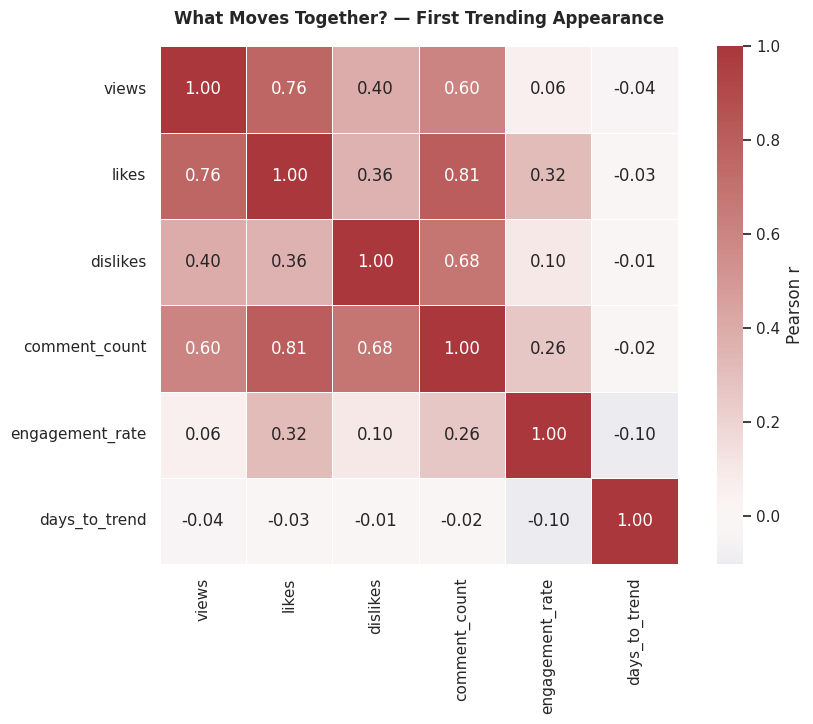

In [8]:
plt.figure(figsize=(9.5, 7.4))
sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f',
    cmap='vlag',
    center=0,
    square=True,
    linewidths=.7,
    cbar_kws={'label': 'Pearson r'}
)
plt.title('What Moves Together? — First Trending Appearance', pad=16, weight='bold')
plt.xlabel('')
plt.ylabel('')
plt.tight_layout()
plt.savefig(visual_dir / '01 correlation heatmap.png', dpi=180, bbox_inches='tight')
plt.show()

### Reading The Matrix

- `views` and `likes` remain strongly aligned, but the relationship is not perfect.
- `likes` and `comment_count` move together more strongly than `views` and `engagement_rate`.
- `days_to_trend` is only weakly related to raw popularity metrics; speed to trend and eventual reach are different signals.

## 7. Category Benchmarking

The required benchmark uses averages for views, engagement rate, and like rate. Video count and medians are shown alongside them because category sizes and outliers differ substantially.

In [9]:
category_benchmark = (
    df.groupby('category_name')
      .agg(
          video_count=('video_id', 'count'),
          avg_views=('views', 'mean'),
          median_views=('views', 'median'),
          avg_engagement_rate=('engagement_rate', 'mean'),
          median_engagement_rate=('engagement_rate', 'median'),
          avg_like_rate=('like_rate', 'mean'),
          median_days_to_trend=('days_to_trend', 'median')
      )
      .sort_values('avg_views', ascending=False)
)
category_benchmark.round(3)

,video_count,avg_views,median_views,avg_engagement_rate,median_engagement_rate,avg_like_rate,median_days_to_trend
category_name,,,,,,,
Music,799,"1,387,621.184","360,001.000",8.234,7.255,7.402,1.000
Gaming,103,"1,211,843.796","652,300.000",5.483,5.375,4.380,1.000
Nonprofits & Activism,14,"1,025,216.571","28,775.500",4.831,2.984,3.745,3.000
Film & Animation,318,"920,433.028","371,256.500",4.029,3.347,3.397,2.000
Sports,451,"830,281.528","305,899.000",2.039,1.571,1.612,1.000
Entertainment,1619,"817,123.090","319,412.000",3.843,2.996,3.205,2.000
Comedy,547,"772,954.612","468,522.000",5.689,4.794,4.971,1.000
People & Blogs,498,"712,767.502","224,029.000",5.505,4.410,4.700,2.000
Science & Technology,380,"584,322.489","236,786.000",4.231,3.815,3.581,2.000


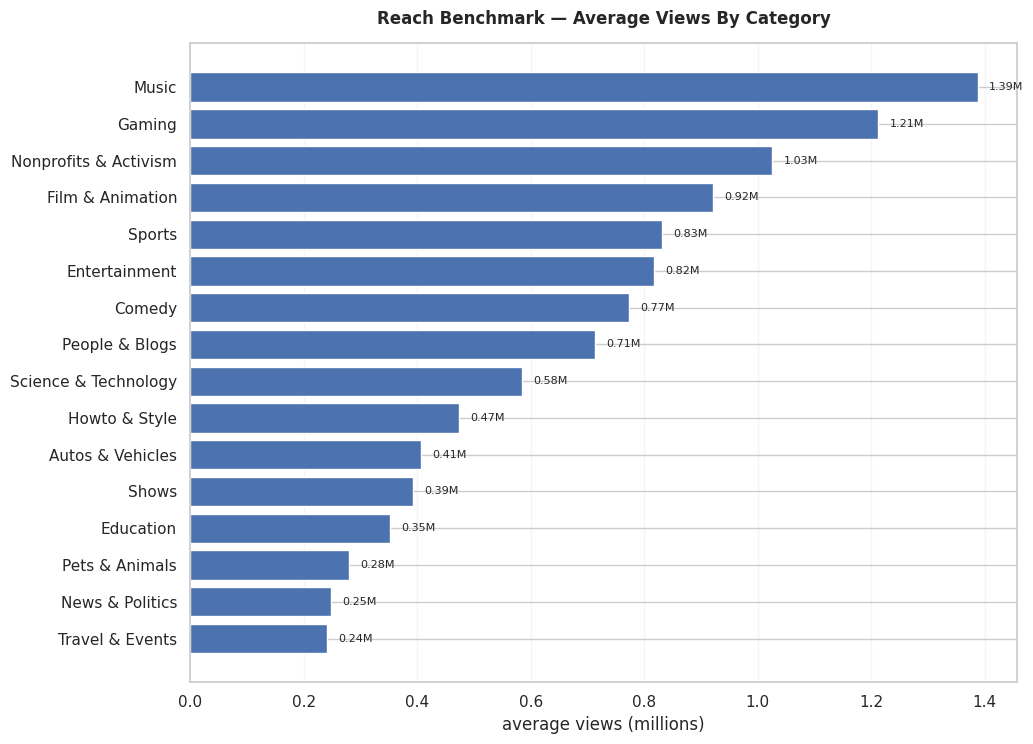

In [10]:
views_chart = category_benchmark.sort_values('avg_views')

plt.figure(figsize=(10.5, 7.6))
bars = plt.barh(views_chart.index, views_chart['avg_views'] / 1_000_000)
plt.title('Reach Benchmark — Average Views By Category', pad=14, weight='bold')
plt.xlabel('average views (millions)')
plt.ylabel('')
plt.grid(axis='x', alpha=.2)

# labels stay outside the bars to avoid collisions with shorter categories
for bar, value in zip(bars, views_chart['avg_views'] / 1_000_000):
    plt.text(value + .02, bar.get_y() + bar.get_height()/2, f'{value:.2f}M', va='center', fontsize=8)

plt.tight_layout()
plt.savefig(visual_dir / '02 average views by category.png', dpi=180, bbox_inches='tight')
plt.show()

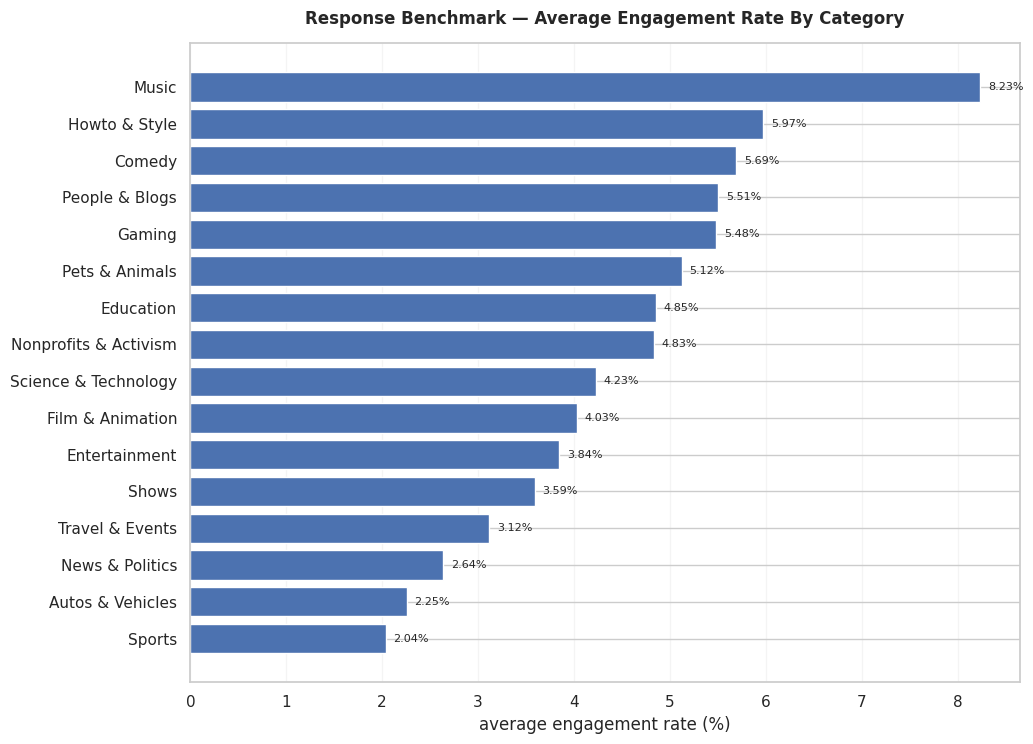

In [11]:
engagement_chart = category_benchmark.sort_values('avg_engagement_rate')

plt.figure(figsize=(10.5, 7.6))
bars = plt.barh(engagement_chart.index, engagement_chart['avg_engagement_rate'])
plt.title('Response Benchmark — Average Engagement Rate By Category', pad=14, weight='bold')
plt.xlabel('average engagement rate (%)')
plt.ylabel('')
plt.grid(axis='x', alpha=.2)

for bar, value in zip(bars, engagement_chart['avg_engagement_rate']):
    plt.text(value + .08, bar.get_y() + bar.get_height()/2, f'{value:.2f}%', va='center', fontsize=8)

plt.tight_layout()
plt.savefig(visual_dir / '03 engagement rate by category.png', dpi=180, bbox_inches='tight')
plt.show()

## 8. Does Publishing Weekday Change Reach?

Views are heavily right-skewed, so the analysis reports both mean and median and uses a logarithmic y-axis in the required boxplot. A weekday with the highest mean is not automatically a causal “best day” — category mix, creator size, and campaign timing are uncontrolled.

In [12]:
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

weekday_summary = (
    df.groupby('publish_weekday')
      .agg(
          video_count=('video_id', 'count'),
          avg_views=('views', 'mean'),
          median_views=('views', 'median'),
          avg_engagement_rate=('engagement_rate', 'mean')
      )
      .reindex(weekday_order)
)
weekday_summary.round(2)

,video_count,avg_views,median_views,avg_engagement_rate
publish_weekday,,,,
Monday,985,"750,340.860","254,444.000",4.380
Tuesday,1061,"722,556.560","250,242.000",4.570
Wednesday,1097,"677,738.520","268,548.000",4.760
Thursday,1055,"713,014.400","291,258.000",5.020
Friday,1047,"894,334.040","264,767.000",5.240
Saturday,547,"726,031.160","288,208.000",4.880
Sunday,559,"859,489.380","296,633.000",4.320


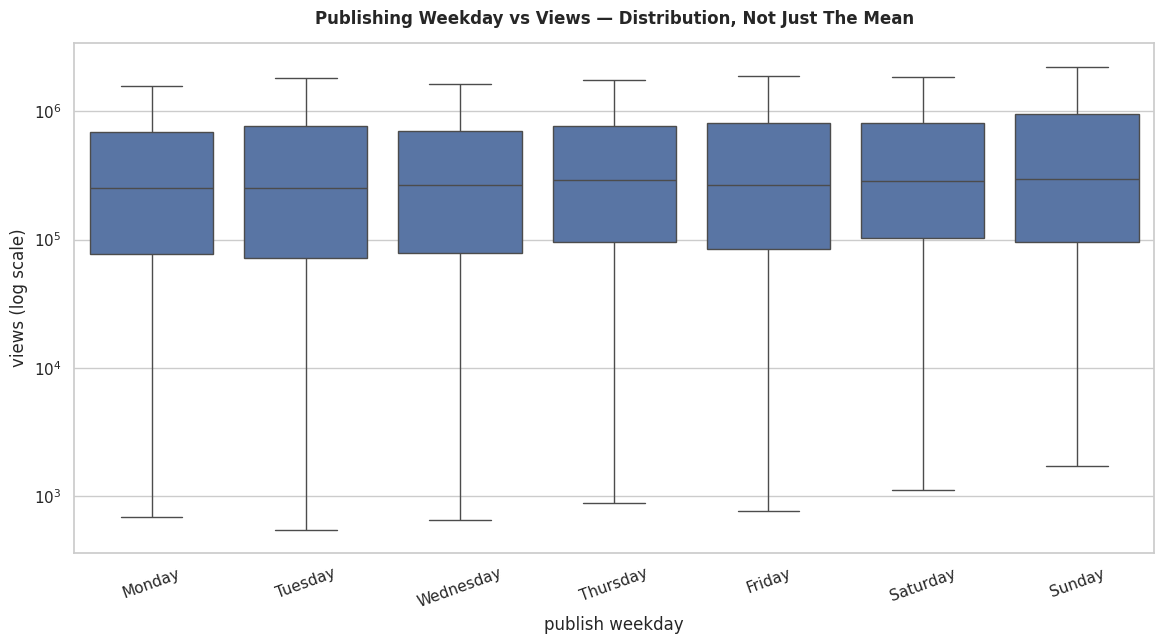

In [13]:
plt.figure(figsize=(11.8, 6.6))
sns.boxplot(
    data=df,
    x='publish_weekday',
    y='views',
    order=weekday_order,
    showfliers=False
)
plt.yscale('log')
plt.title('Publishing Weekday vs Views — Distribution, Not Just The Mean', pad=14, weight='bold')
plt.xlabel('publish weekday')
plt.ylabel('views (log scale)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(visual_dir / '04 views by publish weekday boxplot.png', dpi=180, bbox_inches='tight')
plt.show()

## 9. Top 10 Trending Videos By First-Appearance Views

This ranking inspects the highest-reach first trending snapshots and keeps category plus `days_to_trend` visible, making speed and scale readable together.

In [14]:
top_10 = (
    df.nlargest(10, 'views')[[
        'title', 'channel_title', 'category_name', 'views',
        'engagement_rate', 'like_rate', 'days_to_trend'
    ]]
    .reset_index(drop=True)
)
top_10.index = top_10.index + 1
top_10.round({'engagement_rate': 2, 'like_rate': 2})

,title,channel_title,category_name,views,engagement_rate,like_rate,days_to_trend
1,Maluma - El Préstamo (Official Video),MalumaVEVO,Music,48431654,1.430,1.260,6
2,BTS (방탄소년단) 'FAKE LOVE' Official MV,ibighit,Music,39349927,11.800,9.860,1
3,TWICE What is Love? M/V,jypentertainment,Music,38873543,3.640,2.860,5
4,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,Entertainment,37736281,5.300,4.600,1
5,Ed Sheeran - Perfect (Official Music Video),Ed Sheeran,Music,33523622,5.190,4.870,5
6,Childish Gambino - This Is America (Official V...,ChildishGambinoVEVO,Music,31648454,5.080,4.440,2
7,VENOM - Official Trailer (HD),Sony Pictures Entertainment,Entertainment,27973210,3.480,3.040,1
8,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,Entertainment,24782158,8.450,4.640,1
9,Drake - Nice For What,DrakeVEVO,Music,24421448,2.870,2.630,7
10,Sanju | Official Trailer | Ranbir Kapoor | Raj...,FoxStarHindi,Entertainment,23758250,2.740,2.470,2


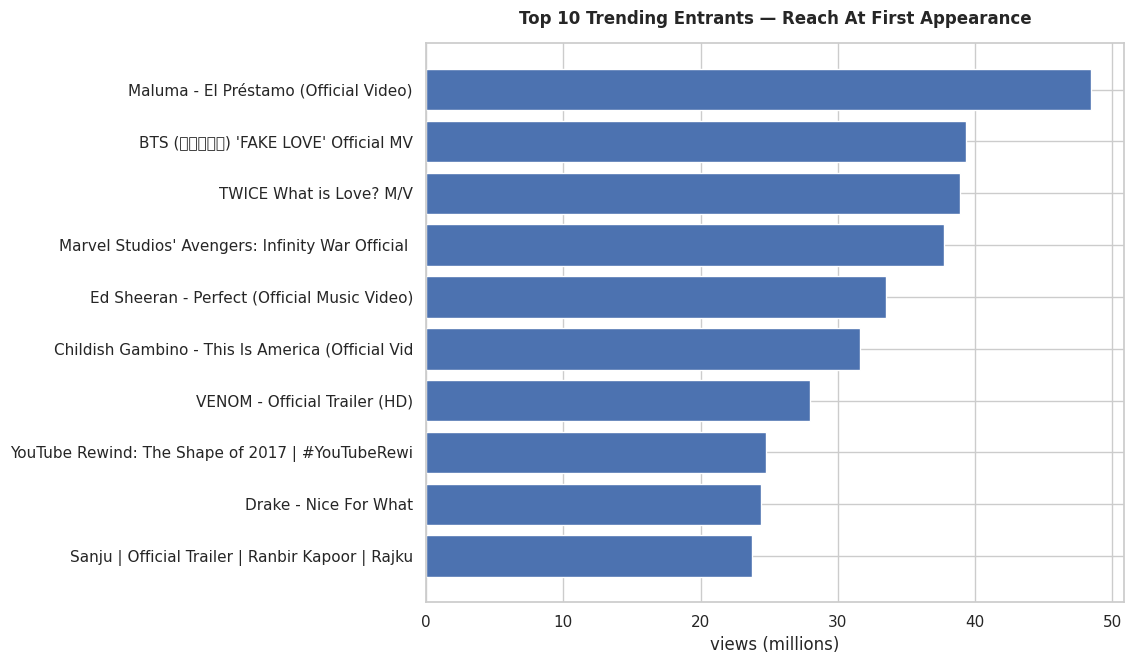

In [15]:
plot_top = top_10.sort_values('views')

plt.figure(figsize=(11.5, 6.8))
plt.barh(plot_top['title'].str.slice(0, 48), plot_top['views'] / 1_000_000)
plt.title('Top 10 Trending Entrants — Reach At First Appearance', pad=14, weight='bold')
plt.xlabel('views (millions)')
plt.ylabel('')
plt.tight_layout()
plt.savefig(visual_dir / '05 top 10 first appearance views.png', dpi=180, bbox_inches='tight')
plt.show()

# Addition — Grain Sensitivity Check

The source contains repeated daily snapshots for the same video. Comparing correlations **before** and **after** the required first-appearance filter shows why analytical grain is not a cosmetic choice.

In [16]:
raw_rates = raw.copy()
raw_rates['engagement_rate'] = (
    (raw_rates['likes'] + raw_rates['dislikes'] + raw_rates['comment_count'])
    / raw_rates['views'].replace(0, np.nan) * 100
)

raw_corr = raw_rates[['views', 'likes', 'dislikes', 'comment_count', 'engagement_rate']].corr(method='pearson')
comparison_pairs = [
    ('views ↔ likes', 'views', 'likes'),
    ('views ↔ comments', 'views', 'comment_count'),
    ('dislikes ↔ comments', 'dislikes', 'comment_count'),
    ('likes ↔ comments', 'likes', 'comment_count'),
]

grain_comparison = pd.DataFrame([
    {
        'relationship': label,
        'all trending snapshots': raw_corr.loc[a, b],
        'first appearance only': correlation.loc[a, b]
    }
    for label, a, b in comparison_pairs
]).set_index('relationship')

grain_comparison.round(3)

,all trending snapshots,first appearance only
relationship,,
views ↔ likes,0.849,0.761
views ↔ comments,0.618,0.600
dislikes ↔ comments,0.700,0.680
likes ↔ comments,0.803,0.806


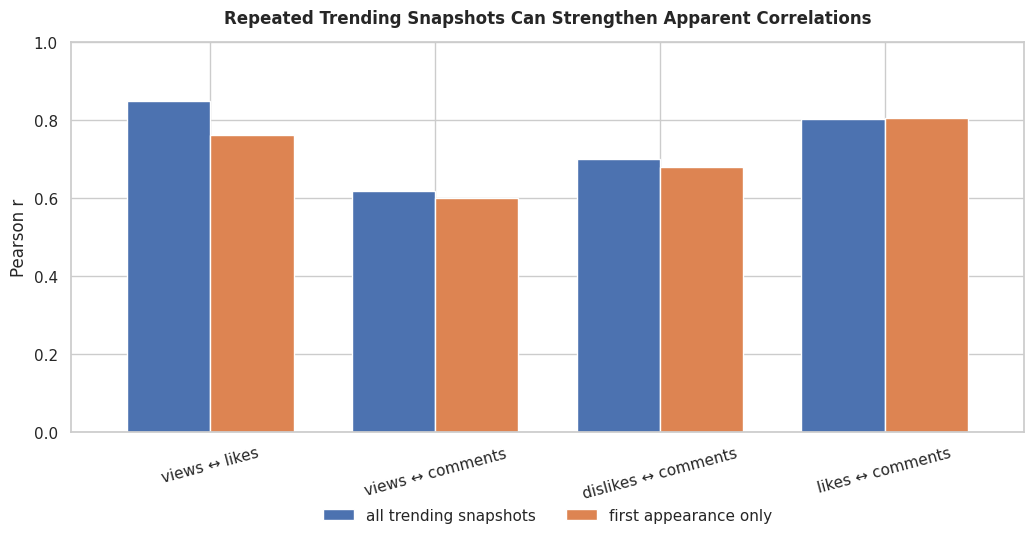

In [17]:
ax = grain_comparison.plot(kind='bar', figsize=(10.5, 5.8), width=.74)
ax.set_title('Repeated Trending Snapshots Can Strengthen Apparent Correlations', pad=14, weight='bold')
ax.set_xlabel('')
ax.set_ylabel('Pearson r')
ax.set_ylim(0, 1)
ax.tick_params(axis='x', rotation=15)
ax.legend(frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.16))
plt.tight_layout()
plt.subplots_adjust(bottom=.24)
plt.savefig(visual_dir / '06 grain sensitivity comparison.png', dpi=180, bbox_inches='tight')
plt.show()

# Addition — Reach / Response Audience Archetypes

Two deliberately strict quartile rules isolate opposite performance profiles:

- **Passive reach:** views in the top quartile, engagement rate in the bottom quartile.
- **Niche loyalty:** views in the bottom quartile, engagement rate in the top quartile.

These are diagnostic segments, not value judgements. A trailer and a community-driven creator video may have very different strategic goals.

In [18]:
views_q25, views_q75 = df['views'].quantile([.25, .75])
eng_q25, eng_q75 = df['engagement_rate'].quantile([.25, .75])

passive_reach = df[
    (df['views'] >= views_q75) &
    (df['engagement_rate'] <= eng_q25)
].copy()

niche_loyal = df[
    (df['views'] <= views_q25) &
    (df['engagement_rate'] >= eng_q75)
].copy()

pd.DataFrame({
    'segment': ['passive reach', 'niche loyalty'],
    'video_count': [len(passive_reach), len(niche_loyal)],
    'median_views': [passive_reach['views'].median(), niche_loyal['views'].median()],
    'median_engagement_rate': [
        passive_reach['engagement_rate'].median(),
        niche_loyal['engagement_rate'].median()
    ]
}).round(2)

,segment,video_count,median_views,median_engagement_rate
0,passive reach,335,"1,421,492.000",1.190
1,niche loyalty,352,"37,938.500",8.990


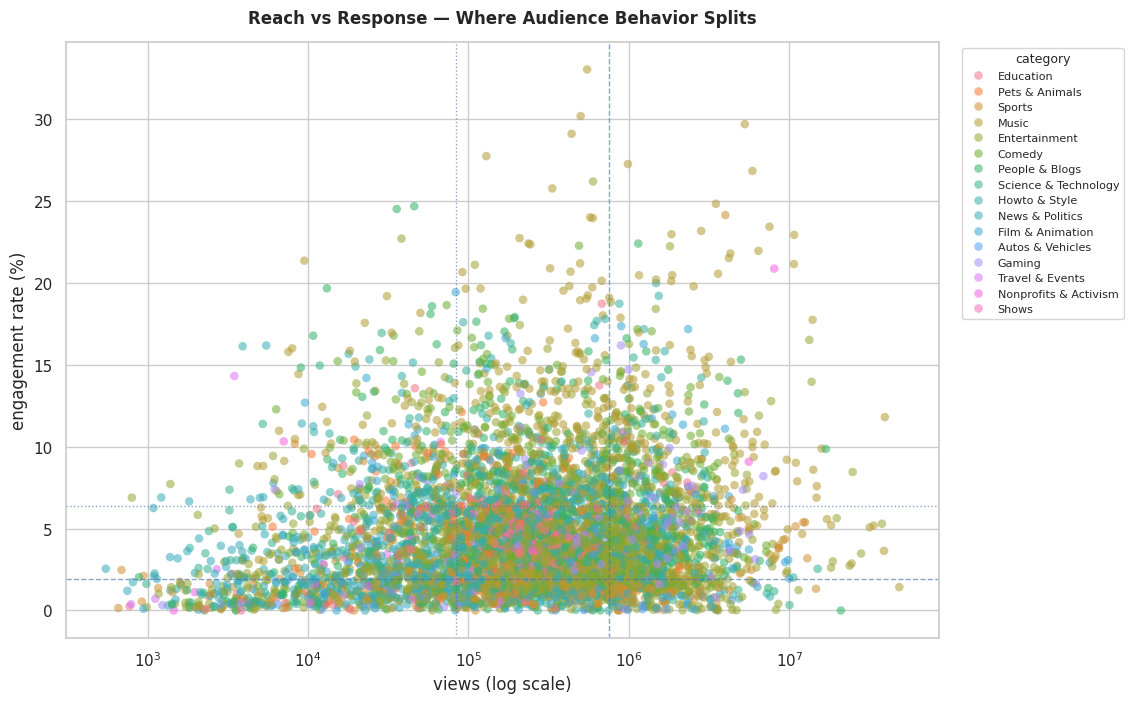

In [19]:
plt.figure(figsize=(11.5, 7.2))
sns.scatterplot(
    data=df,
    x='views',
    y='engagement_rate',
    hue='category_name',
    alpha=.55,
    s=38,
    linewidth=0
)
plt.xscale('log')
plt.axvline(views_q75, linestyle='--', linewidth=1, alpha=.65)
plt.axhline(eng_q25, linestyle='--', linewidth=1, alpha=.65)
plt.axvline(views_q25, linestyle=':', linewidth=1, alpha=.65)
plt.axhline(eng_q75, linestyle=':', linewidth=1, alpha=.65)
plt.title('Reach vs Response — Where Audience Behavior Splits', pad=14, weight='bold')
plt.xlabel('views (log scale)')
plt.ylabel('engagement rate (%)')
plt.legend(title='category', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8, title_fontsize=9)
plt.tight_layout()
plt.savefig(visual_dir / '07 reach vs engagement by category.png', dpi=180, bbox_inches='tight')
plt.show()

In [20]:
# interactive hover makes individual titles, categories, and trend speed inspectable without crowding the static chart
interactive = px.scatter(
    df,
    x='views',
    y='engagement_rate',
    color='category_name',
    hover_name='title',
    hover_data={
        'channel_title': True,
        'days_to_trend': True,
        'like_rate': ':.2f',
        'views': ':,',
        'engagement_rate': ':.2f'
    },
    log_x=True,
    title='Interactive Reach vs Engagement — First Trending Appearance'
)
interactive.update_layout(
    legend_title_text='Category',
    xaxis_title='Views (log scale)',
    yaxis_title='Engagement rate (%)',
    template='plotly_white',
    height=700
)
interactive.write_html(visual_dir / '08 interactive reach vs engagement.html', include_plotlyjs='cdn')
interactive.show()

# Addition — Trend Velocity By Category

`days_to_trend` contains a long tail of old videos that later resurfaced. Median days are therefore more useful for typical velocity than category means. To avoid unstable conclusions, the chart below only shows categories with at least 50 first-appearance videos.

In [21]:
velocity = (
    df.groupby('category_name')
      .agg(
          video_count=('video_id', 'count'),
          median_days_to_trend=('days_to_trend', 'median'),
          p75_days_to_trend=('days_to_trend', lambda s: s.quantile(.75))
      )
      .query('video_count >= 50')
      .sort_values(['median_days_to_trend', 'p75_days_to_trend'])
)
velocity

,video_count,median_days_to_trend,p75_days_to_trend
category_name,,,
Comedy,547,1.000,2.000
Gaming,103,1.000,2.000
News & Politics,505,1.000,2.000
Sports,451,1.000,2.000
Music,799,1.000,3.000
Entertainment,1619,2.000,2.000
Education,250,2.000,3.000
Film & Animation,318,2.000,3.000
Howto & Style,595,2.000,3.000


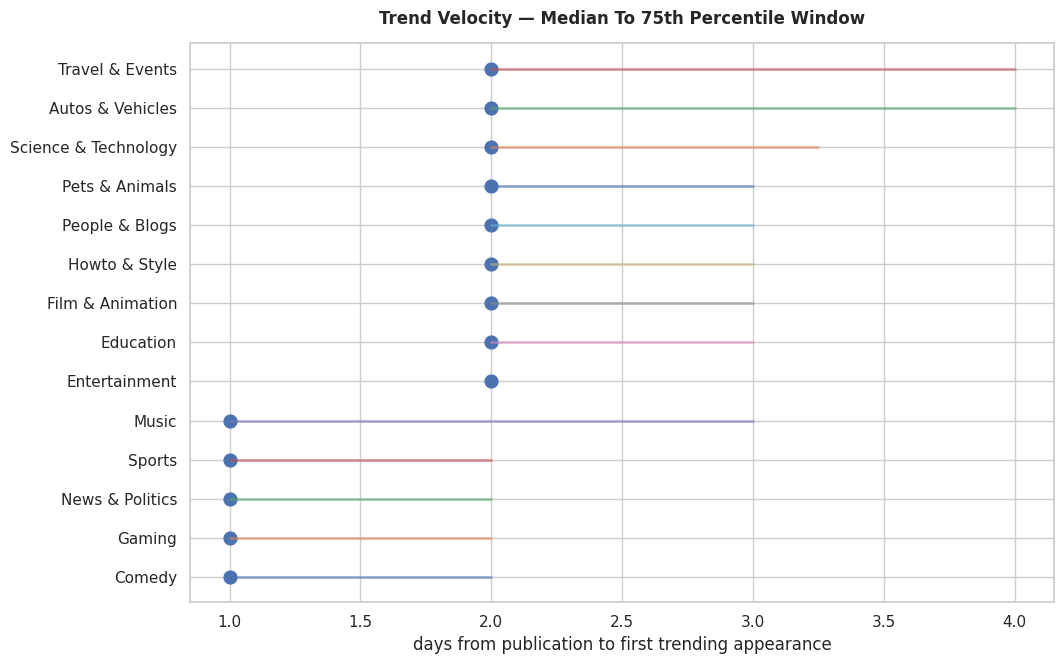

In [22]:
plt.figure(figsize=(10.8, 6.8))
plt.scatter(velocity['median_days_to_trend'], velocity.index, s=85)
for category, row in velocity.iterrows():
    plt.plot(
        [row['median_days_to_trend'], row['p75_days_to_trend']],
        [category, category],
        linewidth=2,
        alpha=.55
    )
plt.title('Trend Velocity — Median To 75th Percentile Window', pad=14, weight='bold')
plt.xlabel('days from publication to first trending appearance')
plt.ylabel('')
plt.tight_layout()
plt.savefig(visual_dir / '09 category trend velocity.png', dpi=180, bbox_inches='tight')
plt.show()

# Addition — Metadata Density Reality Check

Tag volume is easy to optimize mechanically, so it is useful to test whether “more tags” tracks reach or engagement in this dataset. The relationship is measured, not assumed.

In [23]:
tag_relationship = pd.Series({
    'tag_count vs views': df[['tag_count', 'views']].corr().iloc[0, 1],
    'tag_count vs engagement_rate': df[['tag_count', 'engagement_rate']].corr().iloc[0, 1]
})
tag_relationship.to_frame('Pearson r').round(3)

,Pearson r
tag_count vs views,0.042
tag_count vs engagement_rate,-0.038


## 10. Five Content-Strategy Insights

**1. Music combines scale and response at first trend entry.** Among categories with meaningful volume, Music leads average views and also has the highest average engagement rate. Large reach does not necessarily imply passive behavior.

**2. Raw popularity metrics move together more than normalized engagement does.** Likes and comments correlate strongly with one another, while views and engagement rate are nearly independent. A large audience and an active audience are different objectives.

**3. First-appearance grain materially changes the story.** Repeated daily trending snapshots strengthen some raw-count correlations. Removing those repeats lowers `views ↔ likes`, showing why grain control belongs in the analytical method rather than in a footnote.

**4. Weekday differences exist, but the distributions overlap heavily.** Friday has the highest mean views in this first-appearance sample, while Sunday has the highest median. The boxplot shows enough overlap that weekday should be treated as a scheduling context, not a standalone growth lever.

**5. Trend speed is usually short, but the tail is long.** Most high-volume categories have a median of only one to two days to first trend appearance; category means are much higher because older videos can resurface. For launch planning, median velocity is the more representative benchmark.

## 11. Completion Snapshot

The notebook covers every required output: metric engineering, first-appearance deduplication, Pearson correlation + heatmap, category benchmarking, publish-weekday analysis, top-10 inspection, and five content-strategy insights. The **Addition** sections extend the work with grain sensitivity, audience archetypes, an interactive category scatter, trend-velocity diagnostics, and a metadata-density check.